# Classificador de Máxima Correlação

*Implementação com scikit-learn · base processada (sem duplicatas, z-score)*

Cada classe é representada pelo seu centroide $\mathbf{m}_i$. A amostra é atribuída à classe de maior correlação (cosseno do ângulo) com ela:

$$\hat{y}(\mathbf{x}) = \arg\max_i \frac{\mathbf{x}^\top \mathbf{m}_i}{\|\mathbf{x}\|\,\|\mathbf{m}_i\|}$$

Como $\|\mathbf{x}\|$ é o mesmo para todas as classes, basta normalizar os centroides.

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=True)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5406 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import NearestCentroid


class MaximaCorrelacao(ClassifierMixin, BaseEstimator):
    """O scikit-learn não possui este classificador: reaproveita os centroides do NearestCentroid."""

    def fit(self, X, y):
        nc = NearestCentroid().fit(X, y)
        self.classes_ = nc.classes_
        self.prototipos_ = nc.centroids_ / np.linalg.norm(nc.centroids_, axis=1, keepdims=True)
        return self

    def predict(self, X):
        return self.classes_[(X @ self.prototipos_.T).argmax(axis=1)]  # maior cosseno


MODELOS = {"Máxima correlação": MaximaCorrelacao()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn", "max_correlacao")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,Máxima correlação,0.7053,0.0156,0.7454,0.6760,0.7025,1.7788,0.2210
30/70,Máxima correlação,0.7062,0.0136,0.7392,0.6757,0.7045,2.0739,0.2195
50/50,Máxima correlação,0.7068,0.0111,0.7425,0.6778,0.7066,2.1112,0.1606
70/30,Máxima correlação,0.7051,0.0106,0.7300,0.6831,0.7050,2.6743,0.1325
80/20,Máxima correlação,0.7051,0.0130,0.7311,0.6774,0.7070,2.3076,0.1054


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

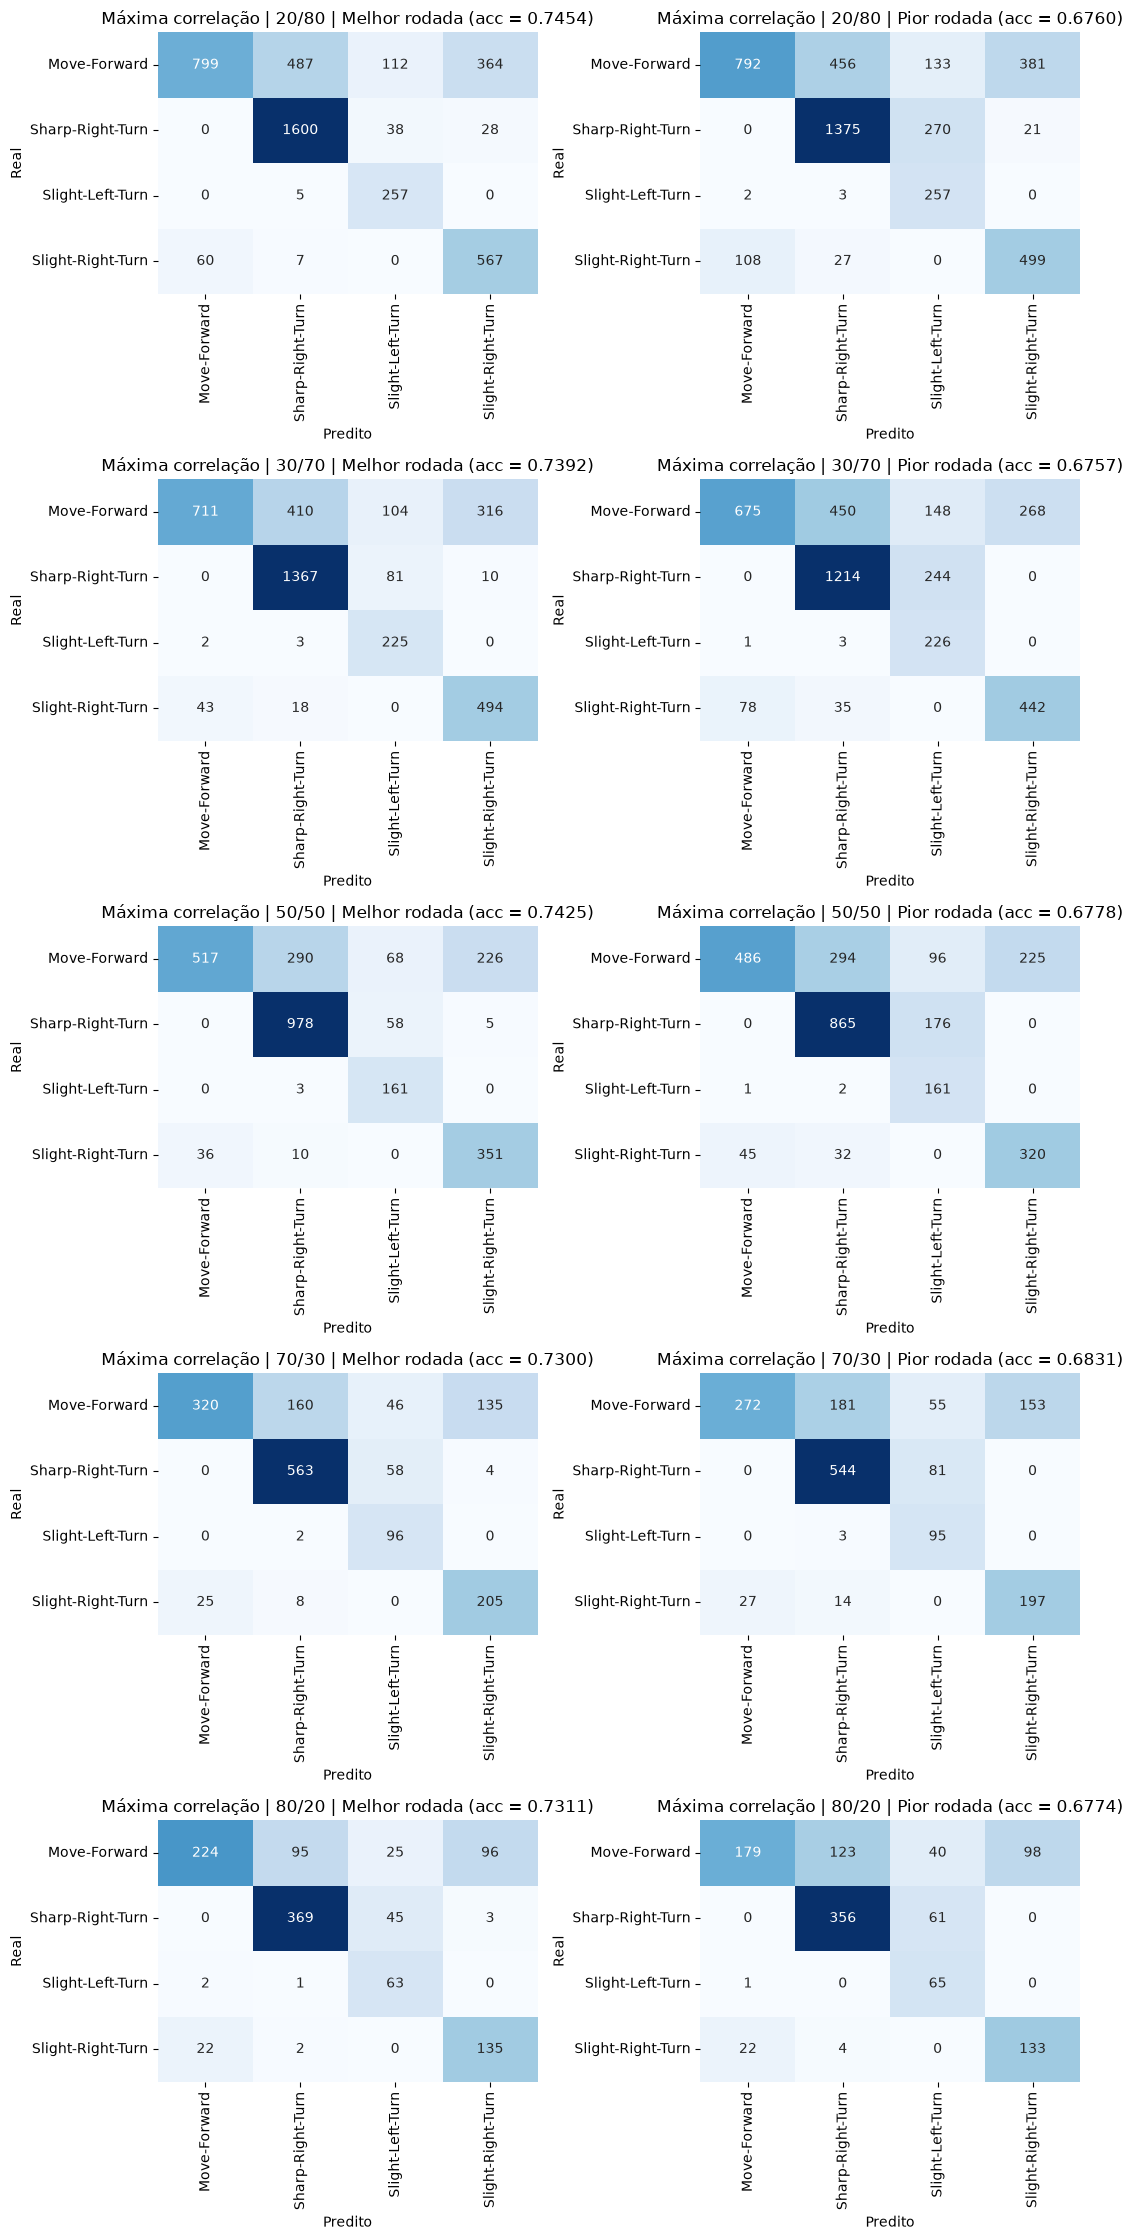

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

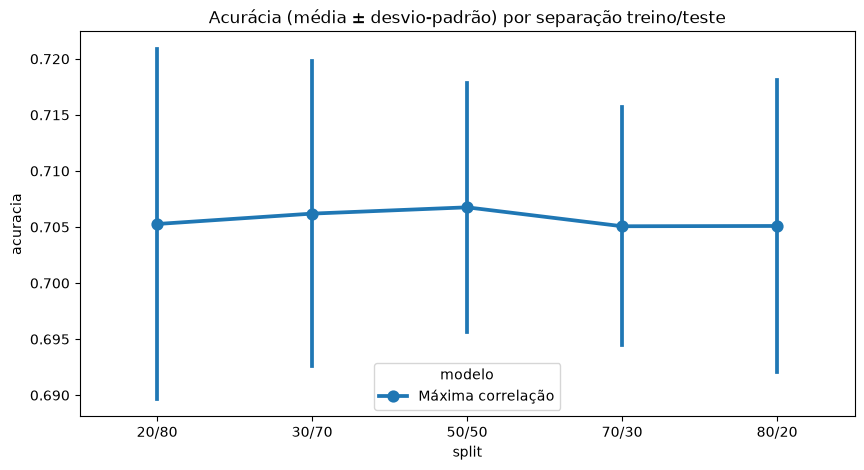

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  \
classe            split modelo                                              
Move-Forward      20/80 Máxima correlação  0.4490  0.0142  0.4989  0.4234   
                  30/70 Máxima correlação  0.4493  0.0131  0.4971  0.4192   
                  50/50 Máxima correlação  0.4480  0.0120  0.4805  0.4160   
                  70/30 Máxima correlação  0.4462  0.0179  0.4856  0.4054   
                  80/20 Máxima correlação  0.4445  0.0237  0.5091  0.3886   
Sharp-Right-Turn  20/80 Máxima correlação  0.8794  0.0298  0.9604  0.8253   
                  30/70 Máxima correlação  0.8817  0.0261  0.9438  0.8326   
                  50/50 Máxima correlação  0.8813  0.0195  0.9395  0.8309   
                  70/30 Máxima correlação  0.8778  0.0154  0.9232  0.8464   
                  80/20 Máxima correlação  0.8787  0.0176  0.9329  0.8297   
Slight-Left-Turn  20/80 Máxima correlação  0.9809  0.0081  1.0000  0.9618   
                  30/70 Máxima correlação  0.9804  0.0066  1.0000  0.9609   
                  50/50 Máxima correlação  0.9822  0.0073  0.9939  0.9634   
                  70/30 Máxima correlação  0.9818  0.0124  1.0000  0.9388   
                  80/20 Máxima correlação  0.9811  0.0137  1.0000  0.9545   
Slight-Right-Turn 20/80 Máxima correlação  0.8461  0.0278  0.9038  0.7666   
                  30/70 Máxima correlação  0.8446  0.0304  0.9279  0.7694   
                  50/50 Máxima correlação  0.8529  0.0216  0.9421  0.8060   
                  70/30 Máxima correlação  0.8566  0.0217  0.9076  0.7941   
                  80/20 Máxima correlação  0.8563  0.0295  0.9371  0.7736   

                                           mediana  
classe            split modelo                      
Move-Forward      20/80 Máxima correlação   0.4475  
                  30/70 Máxima correlação   0.4481  
                  50/50 Máxima correlação   0.4478  
                  70/30 Máxima correlação   0.4455  
                  80/20 Máxima correlação   0.4432  
Sharp-Right-Turn  20/80 Máxima correlação   0.8727  
                  30/70 Máxima correlação   0.8759  
                  50/50 Máxima correlação   0.8799  
                  70/30 Máxima correlação   0.8768  
                  80/20 Máxima correlação   0.8801  
Slight-Left-Turn  20/80 Máxima correlação   0.9809  
                  30/70 Máxima correlação   0.9826  
                  50/50 Máxima correlação   0.9817  
                  70/30 Máxima correlação   0.9796  
                  80/20 Máxima correlação   0.9848  
Slight-Right-Turn 20/80 Máxima correlação   0.8478  
                  30/70 Máxima correlação   0.8459  
                  50/50 Máxima correlação   0.8514  
                  70/30 Máxima correlação   0.8571  
                  80/20 Máxima correlação   0.8553

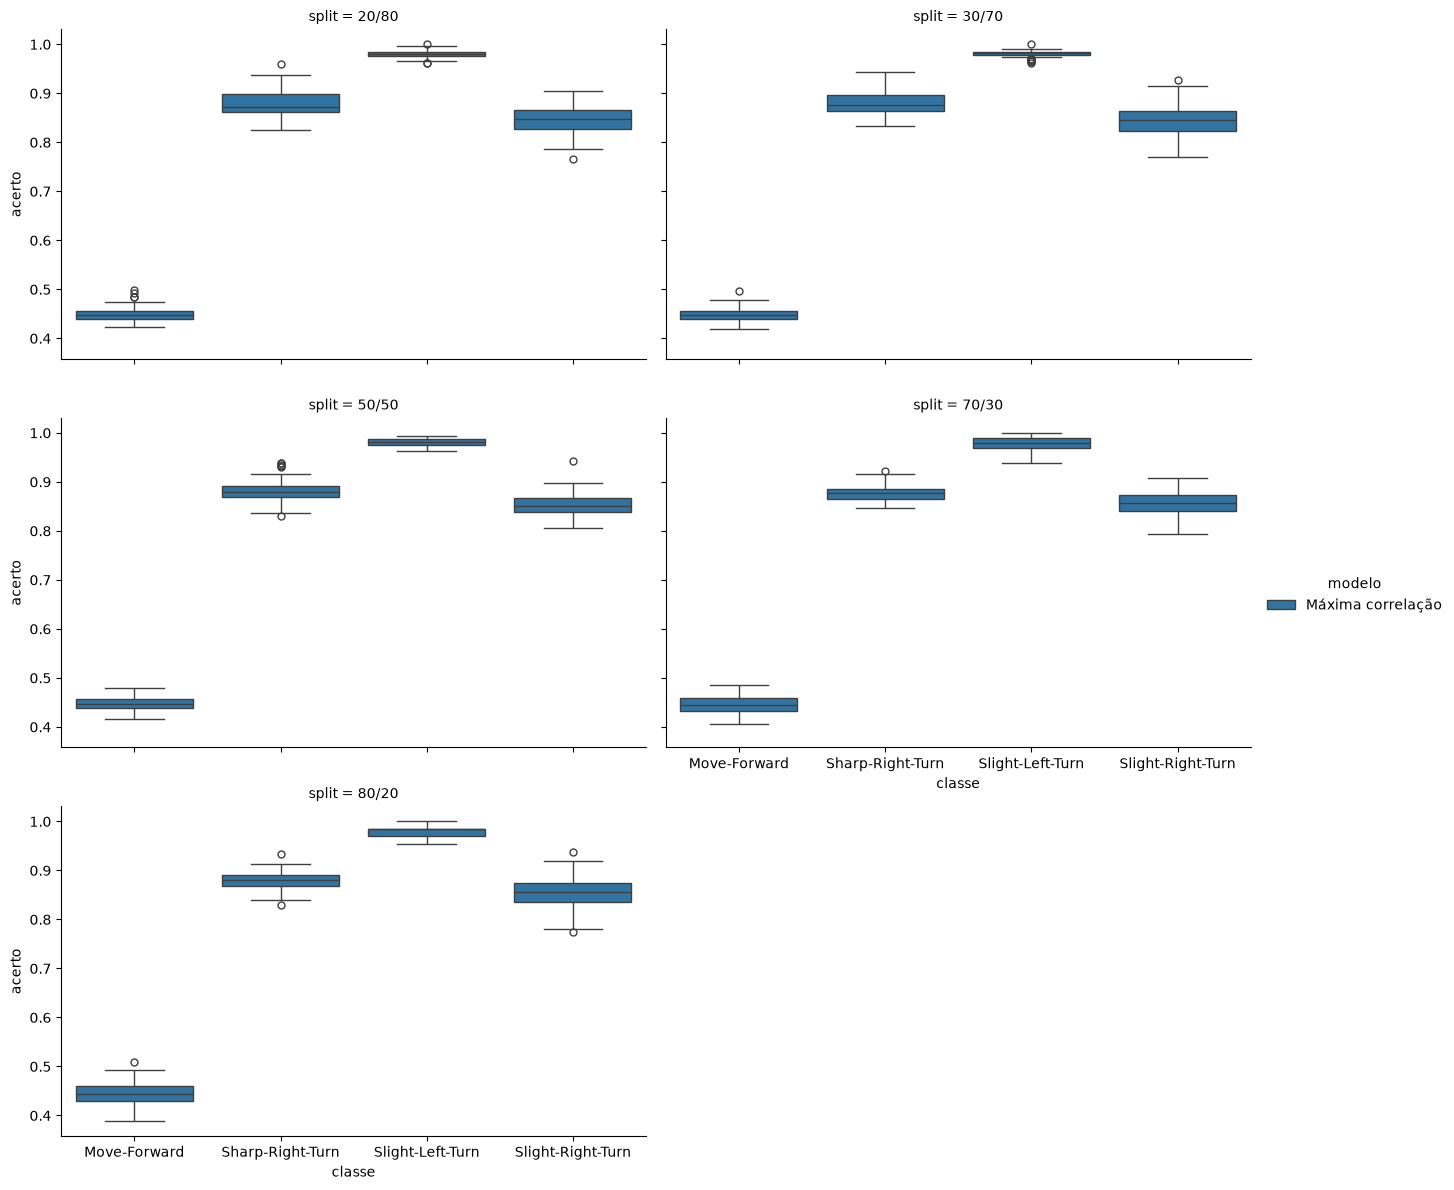

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: Máxima correlação com split 50/50 -> acurácia média 0.7068

Tempo médio por rodada (ms):
  Máxima correlação: treino 2.189 | teste 0.168

Efeito do split (acurácia média 20/80 -> 80/20):
  Máxima correlação: 0.7053 -> 0.7051 (-0.0002)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.4474
  Slight-Right-Turn: 0.8513
  Sharp-Right-Turn: 0.8798
  Slight-Left-Turn: 0.9813
Classe mais fácil: Slight-Left-Turn | mais difícil: Move-Forward
